In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/adrianboguszewski/landcoverai/split.py
/kaggle/input/datasets/adrianboguszewski/landcoverai/test.txt
/kaggle/input/datasets/adrianboguszewski/landcoverai/train.txt
/kaggle/input/datasets/adrianboguszewski/landcoverai/val.txt
/kaggle/input/datasets/adrianboguszewski/landcoverai/images/M-33-20-D-c-4-2.tif
/kaggle/input/datasets/adrianboguszewski/landcoverai/images/M-33-20-D-d-3-3.tif
/kaggle/input/datasets/adrianboguszewski/landcoverai/images/M-33-32-B-b-4-4.tif
/kaggle/input/datasets/adrianboguszewski/landcoverai/images/M-33-48-A-c-4-4.tif
/kaggle/input/datasets/adrianboguszewski/landcoverai/images/M-33-7-A-d-2-3.tif
/kaggle/input/datasets/adrianboguszewski/landcoverai/images/M-33-7-A-d-3-2.tif
/kaggle/input/datasets/adrianboguszewski/landcoverai/images/M-34-32-B-a-4-3.tif
/kaggle/input/datasets/adrianboguszewski/landcoverai/images/M-34-32-B-b-1-3.tif
/kaggle/input/datasets/adrianboguszewski/landcoverai/images/M-34-5-D-d-4-2.tif
/kaggle/input/datasets/adrianbogusz

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("adrianboguszewski/landcoverai")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/adrianboguszewski/landcoverai


In [3]:
import os

for root, dirs, files in os.walk(path):
    print("Folder:", root)
    print("Subfolders:", dirs)
    print("Files count:", len(files), "| Sample files:", files[:5])
    print("-" * 50)

Folder: /kaggle/input/datasets/adrianboguszewski/landcoverai
Subfolders: ['images', 'masks']
Files count: 4 | Sample files: ['split.py', 'test.txt', 'train.txt', 'val.txt']
--------------------------------------------------
Folder: /kaggle/input/datasets/adrianboguszewski/landcoverai/images
Subfolders: []
Files count: 41 | Sample files: ['M-33-20-D-c-4-2.tif', 'M-33-20-D-d-3-3.tif', 'M-33-32-B-b-4-4.tif', 'M-33-48-A-c-4-4.tif', 'M-33-7-A-d-2-3.tif']
--------------------------------------------------
Folder: /kaggle/input/datasets/adrianboguszewski/landcoverai/masks
Subfolders: []
Files count: 41 | Sample files: ['M-33-20-D-c-4-2.tif', 'M-33-20-D-d-3-3.tif', 'M-33-32-B-b-4-4.tif', 'M-33-48-A-c-4-4.tif', 'M-33-7-A-d-2-3.tif']
--------------------------------------------------


In [4]:
with open(
    "/kaggle/input/datasets/adrianboguszewski/landcoverai/split.py", "r"
) as f:
  print(f.read())

#!/usr/bin/env python3

import glob
import os

import cv2

IMGS_DIR = "./images"
MASKS_DIR = "./masks"
OUTPUT_DIR = "./output"

TARGET_SIZE = 512

img_paths = glob.glob(os.path.join(IMGS_DIR, "*.tif"))
mask_paths = glob.glob(os.path.join(MASKS_DIR, "*.tif"))

img_paths.sort()
mask_paths.sort()

os.makedirs(OUTPUT_DIR)
for i, (img_path, mask_path) in enumerate(zip(img_paths, mask_paths)):
    img_filename = os.path.splitext(os.path.basename(img_path))[0]
    mask_filename = os.path.splitext(os.path.basename(mask_path))[0]
    img = cv2.imread(img_path)
    mask = cv2.imread(mask_path)

    assert img_filename == mask_filename and img.shape[:2] == mask.shape[:2]

    k = 0
    for y in range(0, img.shape[0], TARGET_SIZE):
        for x in range(0, img.shape[1], TARGET_SIZE):
            img_tile = img[y:y + TARGET_SIZE, x:x + TARGET_SIZE]
            mask_tile = mask[y:y + TARGET_SIZE, x:x + TARGET_SIZE]

            if img_tile.shape[0] == TARGET_SIZE and img_tile.shape[1] == TARGET_SIZ

In [5]:
import glob
import os
import cv2
from tqdm import tqdm

DATA_DIR = "/kaggle/input/datasets/adrianboguszewski/landcoverai"
OUT_DIR = "/kaggle/working/processed_data"
TARGET_SIZE = 512

# 1. قراءة قوائم التقسيم الرسمية
splits = {}
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(OUT_DIR, split, "images"), exist_ok=True)
    os.makedirs(os.path.join(OUT_DIR, split, "masks"), exist_ok=True)
    with open(os.path.join(DATA_DIR, f"{split}.txt"), "r") as f:
        splits[split] = set(line.strip() for line in f if line.strip())

# 2. تقطيع الـ 41 صورة بنفس ترقيم split.py وتوزيعهم
img_paths = sorted(glob.glob(os.path.join(DATA_DIR, "images", "*.tif")))
mask_paths = sorted(glob.glob(os.path.join(DATA_DIR, "masks", "*.tif")))

counts = {"train": 0, "val": 0, "test": 0}

for img_path, mask_path in tqdm(zip(img_paths, mask_paths), total=len(img_paths), desc="Splitting Dataset"):
    img_filename = os.path.splitext(os.path.basename(img_path))[0]
    mask_filename = os.path.splitext(os.path.basename(mask_path))[0]
    assert img_filename == mask_filename

    img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
    if mask.ndim == 3:
        mask = mask[:, :, 0]  # توحيد الـ Mask لقناة واحدة (2D)

    k = 0
    for y in range(0, img.shape[0], TARGET_SIZE):
        for x in range(0, img.shape[1], TARGET_SIZE):
            img_tile = img[y:y + TARGET_SIZE, x:x + TARGET_SIZE]
            mask_tile = mask[y:y + TARGET_SIZE, x:x + TARGET_SIZE]

            if img_tile.shape[0] == TARGET_SIZE and img_tile.shape[1] == TARGET_SIZE:
                tile_name = f"{img_filename}_{k}"
                
                for split_name, tile_set in splits.items():
                    if tile_name in tile_set:
                        cv2.imwrite(os.path.join(OUT_DIR, split_name, "images", f"{tile_name}.jpg"), img_tile)
                        cv2.imwrite(os.path.join(OUT_DIR, split_name, "masks", f"{tile_name}.png"), mask_tile)
                        counts[split_name] += 1
                        break
            k += 1

print("\nDone! Final Split Counts:")
for s, c in counts.items():
    print(f"- {s.upper()}: {c} images & masks")

Splitting Dataset:   0%|          | 0/41 [00:00<?, ?it/s][ WARN:0@0.528] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33550 (0x830e) encountered
[ WARN:0@0.529] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33918 (0x847e) encountered
[ WARN:0@0.529] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33922 (0x8482) encountered
[ WARN:0@0.529] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34735 (0x87af) encountered
[ WARN:0@0.529] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34736 (0x87b0) encountered
[ WARN:0@0.529] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34737 (0x87b1) encountered
[ WARN:0@2.396] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33550 (0x830e) encountered
[ WARN:0@2.396] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: U


Done! Final Split Counts:
- TRAIN: 7470 images & masks
- VAL: 1602 images & masks
- TEST: 1602 images & masks


Analyzing Masks: 100%|██████████| 7470/7470 [00:25<00:00, 296.93it/s]



=== Class Distribution (Train Set) ===
Class 0 (Background): 1,134,439,928 pixels (57.93%)
Class 1 (Buildings ):   16,767,238 pixels ( 0.86%)
Class 2 (Woodlands ):  648,714,832 pixels (33.13%)
Class 3 (Water     ):  126,508,305 pixels ( 6.46%)
Class 4 (Roads     ):   31,785,377 pixels ( 1.62%)

=== Recommended Class Weights (للتيم) ===
class_weights = [0.0435, 2.94, 0.076, 0.3897, 1.5509]


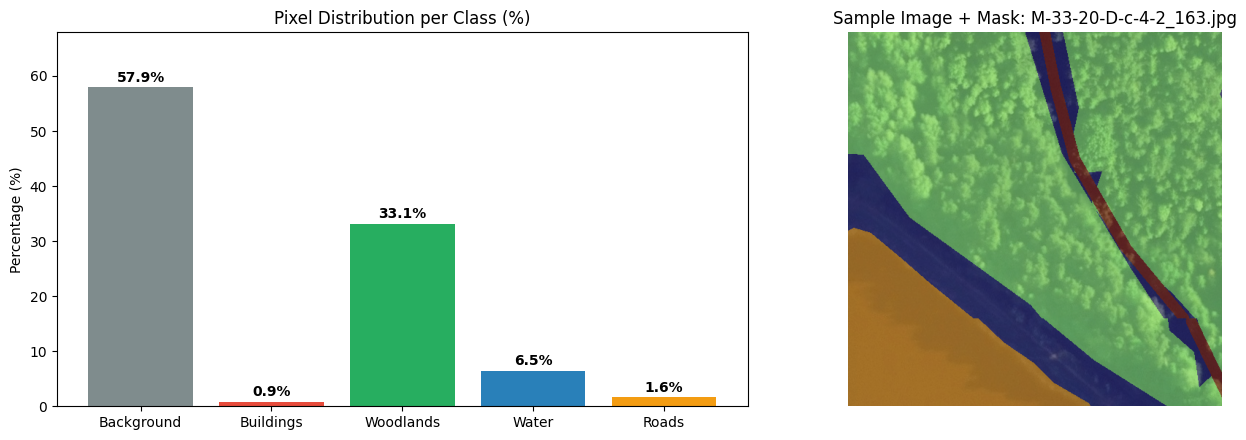

In [6]:
import os
from glob import glob
import cv2
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

TRAIN_IMG_DIR = "/kaggle/working/processed_data/train/images"
TRAIN_MASK_DIR = "/kaggle/working/processed_data/train/masks"

CLASS_NAMES = {
    0: "Background",
    1: "Buildings",
    2: "Woodlands",
    3: "Water",
    4: "Roads"
}

# 1. حساب عدد ونسبة البكسلات لكل كلاس في الـ Train
mask_paths = sorted(glob(os.path.join(TRAIN_MASK_DIR, "*.png")))
pixel_counts = np.zeros(5, dtype=np.int64)

for m_path in tqdm(mask_paths, desc="Analyzing Masks"):
    mask = cv2.imread(m_path, cv2.IMREAD_UNCHANGED)
    counts = np.bincount(mask.ravel(), minlength=5)
    pixel_counts += counts[:5]

total_pixels = pixel_counts.sum()
percentages = (pixel_counts / total_pixels) * 100

# حساب الـ Class Weights (متوازنة بحيث متوسطها = 1)
raw_weights = total_pixels / (5 * pixel_counts)
class_weights = raw_weights / raw_weights.mean()

print("\n=== Class Distribution (Train Set) ===")
for cid, name in CLASS_NAMES.items():
    print(f"Class {cid} ({name:<10}): {pixel_counts[cid]:>12,} pixels ({percentages[cid]:5.2f}%)")

print("\n=== Recommended Class Weights (للتيم) ===")
print("class_weights =", [round(float(w), 4) for w in class_weights])

# 2. رسم التوزيع وعرض صورة عينة بالـ Mask للتقرير
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

names = [CLASS_NAMES[i] for i in range(5)]
colors = ["#7f8c8d", "#e74c3c", "#27ae60", "#2980b9", "#f39c12"]
axes[0].bar(names, percentages, color=colors)
axes[0].set_title("Pixel Distribution per Class (%)")
axes[0].set_ylabel("Percentage (%)")
for i, v in enumerate(percentages):
    axes[0].text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")
axes[0].set_ylim(0, max(percentages) + 10)

# اختيار صورة فيها أكتر من كلاس عشان تبان واضحة في التقرير
sample_idx = 0
for idx, m_path in enumerate(mask_paths[:300]):
    m = cv2.imread(m_path, cv2.IMREAD_UNCHANGED)
    if len(np.unique(m)) >= 4:
        sample_idx = idx
        break

sample_name = os.path.basename(mask_paths[sample_idx]).replace(".png", ".jpg")
sample_img = cv2.cvtColor(cv2.imread(os.path.join(TRAIN_IMG_DIR, sample_name)), cv2.COLOR_BGR2RGB)
sample_mask = cv2.imread(mask_paths[sample_idx], cv2.IMREAD_UNCHANGED)

axes[1].imshow(sample_img)
axes[1].imshow(sample_mask, alpha=0.45, cmap="jet", vmin=0, vmax=4)
axes[1].set_title(f"Sample Image + Mask: {sample_name}")
axes[1].axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/eda_summary.png", dpi=150)
plt.show()

In [7]:
%%writefile /kaggle/working/dataset.py
import os
from glob import glob
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

CLASS_NAMES = ["Background", "Buildings", "Woodlands", "Water", "Roads"]
CLASS_WEIGHTS_RAW = [0.0435, 2.94, 0.076, 0.3897, 1.5509]
CLASS_WEIGHTS_SMOOTH = [0.25, 2.0, 0.33, 0.75, 1.45]

def get_transforms(img_size=512, use_augmentation=True):
    if use_augmentation:
        train_transform = A.Compose([
            A.Resize(img_size, img_size, interpolation=cv2.INTER_LINEAR),
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.RandomRotate90(p=0.5),
            A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.3),
            A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
            ToTensorV2(),
        ])
    else:
        # بدون Augmentation (مفيد لتجربة الـ Ablation Study)
        train_transform = A.Compose([
            A.Resize(img_size, img_size, interpolation=cv2.INTER_LINEAR),
            A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
            ToTensorV2(),
        ])

    val_test_transform = A.Compose([
        A.Resize(img_size, img_size, interpolation=cv2.INTER_LINEAR),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])
    return train_transform, val_test_transform


class LandCoverDataset(Dataset):
    def __init__(self, split_dir, transform=None):
        self.img_paths = sorted(glob(os.path.join(split_dir, "images", "*.jpg")))
        self.mask_paths = sorted(glob(os.path.join(split_dir, "masks", "*.png")))
        assert len(self.img_paths) == len(self.mask_paths), "Mismatch between images and masks!"
        self.transform = transform

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        image = cv2.imread(self.img_paths[idx], cv2.IMREAD_COLOR)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(self.mask_paths[idx], cv2.IMREAD_UNCHANGED)

        if self.transform is not None:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"].long()

        return image, mask


def get_dataloaders(data_root="/kaggle/working/processed_data", batch_size=8, img_size=512, use_augmentation=True, num_workers=2):
    train_tf, val_tf = get_transforms(img_size=img_size, use_augmentation=use_augmentation)

    train_ds = LandCoverDataset(os.path.join(data_root, "train"), transform=train_tf)
    val_ds   = LandCoverDataset(os.path.join(data_root, "val"),   transform=val_tf)
    test_ds  = LandCoverDataset(os.path.join(data_root, "test"),  transform=val_tf)

    # drop_last=True مهم جداً لـ DeepLabV3+ عشان BatchNorm في طبقة ASPP
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=num_workers, pin_memory=True, drop_last=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)

    return train_loader, val_loader, test_loader


if __name__ == "__main__":
    train_loader, val_loader, test_loader = get_dataloaders(batch_size=8, img_size=512)
    imgs, masks = next(iter(train_loader))
    print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")
    print(f"Batch Images Shape: {imgs.shape}, dtype: {imgs.dtype}")
    print(f"Batch Masks  Shape: {masks.shape}, dtype: {masks.dtype}, unique classes: {torch.unique(masks).tolist()}")

Writing /kaggle/working/dataset.py


In [8]:
!python /kaggle/working/dataset.py

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Train batches: 933 | Val batches: 201 | Test batches: 201
Batch Images Shape: torch.Size([8, 3, 512, 512]), dtype: torch.float32
Batch Masks  Shape: torch.Size([8, 512, 512]), dtype: torch.int64, unique classes: [0, 1, 2, 3, 4]
